In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [68]:
file_path = '../data/dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx'
df_users = pd.read_excel(file_path, sheet_name='Пользователи')
df_payments = pd.read_excel(file_path, sheet_name='Платежи')

In [69]:
print(f'Размер таблицы "Пользователи": {df_users.shape}\nРазмер таблицы "Платежи": {df_payments.shape}')

Размер таблицы "Пользователи": (1504, 5)
Размер таблицы "Платежи": (2661, 7)


In [70]:
print(f'Столбцы таблицы "Пользователи": {df_users.columns.to_list()}\nСтолбцы таблицы "Платежи": {df_payments.columns.to_list()}')

Столбцы таблицы "Пользователи": ['user_id', 'group', 'age', 'city', 'device_type']
Столбцы таблицы "Платежи": ['payment_id', 'user_id', 'group', 'step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']


In [71]:
df_users.info()

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB


In [72]:
df_payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   str           
 3   step1_opened     2661 non-null   datetime64[us]
 4   step2_entered    2256 non-null   datetime64[us]
 5   step3_confirmed  1719 non-null   datetime64[us]
 6   step4_success    1522 non-null   datetime64[us]
dtypes: datetime64[us](4), float64(1), int64(1), str(1)
memory usage: 145.7 KB


In [73]:
print('Первые 5 строк в таблицу "Пользователи":')
display(df_users.head())

Первые 5 строк в таблицу "Пользователи":


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [74]:
print('Первые 5 строк в таблицу "Платежи":')
display(df_payments.head())

Первые 5 строк в таблицу "Платежи":


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [75]:
print('Количество пропущенных значений в таблице "Пользователи":')
display(df_users.isna().sum().to_frame('missing_values'))

Количество пропущенных значений в таблице "Пользователи":


,missing_values
user_id,0
group,1
age,0
city,1
device_type,0


In [76]:
print('Количество пропущенных значений в таблице "Платежи":')
display(df_payments.isna().sum().to_frame('missing_values'))

Количество пропущенных значений в таблице "Платежи":


,missing_values
payment_id,0
user_id,1
group,0
step1_opened,0
step2_entered,405
step3_confirmed,942
step4_success,1139


In [77]:
print(f'Полные дубликаты в таблице "Пользователи": {df_users.duplicated().sum()}')
print(f'Дубликаты в user_id таблицы "Пользователи": {df_users["user_id"].duplicated().sum()}')

Полные дубликаты в таблице "Пользователи": 0
Дубликаты в user_id таблицы "Пользователи": 0


In [78]:
print(f'Полные дубликаты в таблице "Платежи": {df_payments.duplicated().sum()}')
print(f'Дубликаты в payment_id таблицы "Платежи": {df_payments["payment_id"].duplicated().sum()}')

Полные дубликаты в таблице "Платежи": 0
Дубликаты в payment_id таблицы "Платежи": 0


In [79]:
print('Распределение групп в таблице "Пользователи":')
display(df_users['group'].value_counts(dropna=False))

Распределение групп в таблице "Пользователи":


group
A      752
B      751
NaN      1
Name: count, dtype: int64

In [80]:
print('Распределение групп в таблице "Платежи":')
display(df_payments['group'].value_counts(dropna=False))

Распределение групп в таблице "Платежи":


group
B    1352
A    1309
Name: count, dtype: int64

In [81]:
print(f'Количество уникальных значений user_id в таблице "Пользователи": {df_users["user_id"].nunique()}')

Количество уникальных значений user_id в таблице "Пользователи": 1504


In [82]:
print(f'Количество уникальных значений user_id в таблице "Платежи": {df_payments["user_id"].nunique()}')

Количество уникальных значений user_id в таблице "Платежи": 1501


In [83]:
print(f'Количество уникальных значений payment_id в таблице "Платежи": {df_payments["payment_id"].nunique()}')

Количество уникальных значений payment_id в таблице "Платежи": 2661


In [84]:
print('Платежи без user_id:')
display(df_payments[df_payments['user_id'].isna()])

Платежи без user_id:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [85]:
print('Пользователи без group:')
display(df_users[df_users['group'].isna()])

Пользователи без group:


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


In [86]:
display(df_payments[df_payments['user_id'] == 9001])

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


Клиент с user_id 9001 не совершал оплат. Следовательно, данных о нем нет в таблице "Платежи" Необходимо удалить этого клиента из таблицы, так как восстановить группу будет невозможно


In [87]:
print('Пользователи без city:')
display(df_users[df_users['city'].isna()])

Пользователи без city:


,user_id,group,age,city,device_type
1503,9004,A,30,NaN,android


In [88]:
payments_users = set(df_payments['user_id'].dropna())
known_users = set(df_users['user_id'])
missing_users = payments_users - known_users
no_payments = known_users - payments_users
print(f'Количество пользователей из платежей, не вошедших в таблицу пользователей: {len(missing_users)}')
print(f'Количество пользователей без платежей: {len(no_payments)}')
display(df_users[df_users['user_id'].isin(no_payments)])

Количество пользователей из платежей, не вошедших в таблицу пользователей: 0
Количество пользователей без платежей: 3


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


Обнаружены три пользователя, которые не совершали платежи. У каждого есть аномалия: отсутствие группы или некорректный возраст. Исключение этих пользователей не повлияет на метрику, так как нет попыток оплаты

In [89]:
payments_per_user = (df_payments.dropna(subset=['user_id'])
                    .groupby('user_id')
                    .agg(n_users = ('payment_id','count')))
payments_per_user

,n_users
user_id,
1001.0,1
1002.0,1
1003.0,1
1004.0,3
1005.0,2
...,...
2497.0,1
2498.0,1
2499.0,3


In [90]:
print(f'Максимальное количество платежей у пользователя: {payments_per_user["n_users"].max()}')

Максимальное количество платежей у пользователя: 4


In [91]:
print(f'Количество пользователей с несколькими платежами: {(payments_per_user["n_users"]>1).sum()}')

Количество пользователей с несколькими платежами: 761


In [92]:
display(payments_per_user.value_counts().sort_values().to_frame('n_users'))
print(f'Процент пользователей несколькими оплатами: {((payments_per_user["n_users"]>1).sum()*100/payments_per_user.shape[0]).round(2)}%')

,n_users
n_users,
4,80
3,238
2,443
1,740


Процент пользователей несколькими оплатами: 50.7%


In [93]:
display(df_users['age'].describe())

count    1504.000000
mean       32.745346
std         8.410915
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64

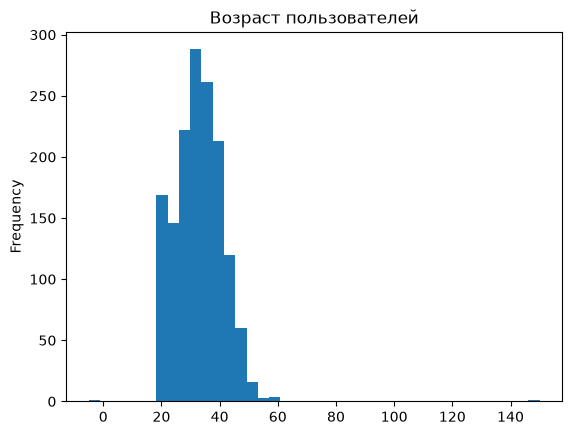

In [94]:
df_users['age'].plot.hist(bins=40, title = 'Возраст пользователей')
plt.show()

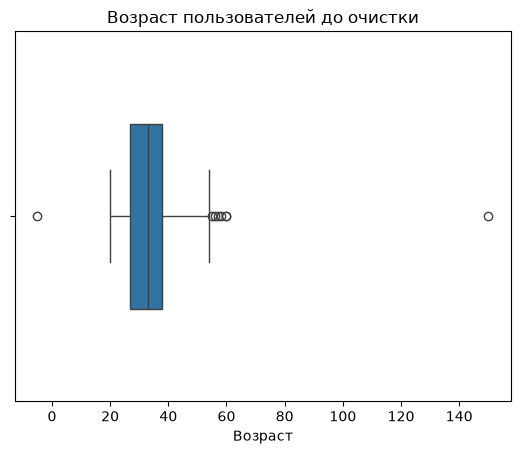

In [95]:
sns.boxplot(data=df_users, x="age", width=.5)
plt.title('Возраст пользователей до очистки')
plt.xlabel('Возраст')
plt.show()

Минимальное значение возраста в таблице "Пользователи" равно -5, а макcимальное 150.

In [96]:
display(df_users[(df_users['age'] < 14) | (df_users['age'] > 100)])

,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


Исключить двух пользователей с невозможным возрастом −5 и 150

In [97]:
display(df_payments[(df_payments['user_id'] == 9002) | (df_payments['user_id'] == 9003 )])

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success


In [98]:
display(df_users['city'].value_counts(dropna=False))

city
Москва    595
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64

In [99]:
display(df_users['device_type'].value_counts(dropna=False))

device_type
android    777
ios        727
Name: count, dtype: int64

Опечаток, разного регистра и пропусков, кроме одного города (определили ранее), нет

In [100]:
users_merge_payments = df_payments.merge(df_users[['user_id', 'group']], on='user_id', how='left', suffixes=('', '_users'))
display(users_merge_payments.head())

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,group_users
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT,A
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT,A
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT,A
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT,A
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,A


In [101]:
display(users_merge_payments[(users_merge_payments['group'] != users_merge_payments['group_users'])])

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,group_users
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT,NaN


Оставим только пользователя без пропуска в user_id

In [102]:
display(users_merge_payments[(users_merge_payments['group_users'].notna()) & (users_merge_payments['group'] != users_merge_payments['group_users'])])

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success,group_users
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A


In [103]:
display(df_users[df_users['user_id'] == 1010])
display(df_payments[df_payments['user_id'] == 1010])

,user_id,group,age,city,device_type
9,1010,A,26,Москва,android


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
14,5015,1010.0,A,2024-04-27 13:26:00,NaT,NaT,NaT
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00


Пользователь с user_id = 1010 имеет 2 записи в таблице "Платежи", но при этом два этих платежа относятся к разным группам. Следует убрать 2 записи данного пользователя, так как невозможно определить к какой точно группе он принадлежит

In [104]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']

for a, b in zip(steps[:-1], steps[1:]):
    no_prev = (df_payments[b].notna() & df_payments[a].isna()).sum()
    neg = ((df_payments[b] - df_payments[a]).dt.total_seconds() < 0).sum()
    print(f'{a} -> {b}: без предыдущего шага={no_prev}, отрицательных интервалов={neg}')

print('Период:', df_payments['step1_opened'].min(), '-', df_payments['step1_opened'].max())

step1_opened -> step2_entered: без предыдущего шага=0, отрицательных интервалов=0
step2_entered -> step3_confirmed: без предыдущего шага=0, отрицательных интервалов=0
step3_confirmed -> step4_success: без предыдущего шага=0, отрицательных интервалов=0
Период: 2024-04-01 00:19:00 - 2024-04-30 23:17:00


In [105]:
for a, b in zip(steps[:-1], steps[1:]):
    d = (df_payments[b] - df_payments[a]).dt.total_seconds() / 60
    print(f'{a} -> {b}')
    display(d.describe().round(1))

step1_opened -> step2_entered


count    2256.0
mean        2.4
std         1.9
min         1.0
25%         1.0
50%         1.0
75%         3.0
max        13.0
dtype: float64

step2_entered -> step3_confirmed


count    1719.0
mean        4.5
std         1.9
min         1.0
25%         3.0
50%         4.0
75%         6.0
max        11.0
dtype: float64

step3_confirmed -> step4_success


count    1522.0
mean        5.5
std         1.1
min         1.0
25%         5.0
50%         6.0
75%         6.0
max         9.0
dtype: float64

In [106]:
clean_users = df_users[(~df_users['group'].isna()) & (df_users['age'].between(14, 100)) & (df_users['user_id'] != 1010)].copy()
print('Количество пропусков в данных:')
display(clean_users.isna().sum())
print(f'Количество строк в таблице "Пользователи" было: {df_users.shape[0]}, стало: {clean_users.shape[0]}')

Количество пропусков в данных:


user_id        0
group          0
age            0
city           1
device_type    0
dtype: int64

Количество строк в таблице "Пользователи" было: 1504, стало: 1500


В отфильтрованной таблице "Пользователи" остался один пропуск в столбце city. Этот пропуск не влияет на качество данных, поэтому удалять его не стоит. В отфильтрованной таблице стало на 4 строки меньше. Две с аномальным возрастом -5 и 150 лет, одна с отсутсвующим значения группы и одна с пользователем с user_id равным 1010, который встречается в двух группах сразу

In [107]:
clean_payments = df_payments[(df_payments['user_id'] != 1010) & (df_payments['user_id'].notna())].copy()
clean_payments['user_id'] = clean_payments['user_id'].astype(int)
print('Количество пропусков в данных:')
display(clean_payments.isna().sum())
print(f'Количество строк в таблице "Платежи" было: {df_payments.shape[0]}, стало: {clean_payments.shape[0]}.\nТип данных столбца user_id: {clean_payments["user_id"].dtype}')

Количество пропусков в данных:


payment_id            0
user_id               0
group                 0
step1_opened          0
step2_entered       403
step3_confirmed     940
step4_success      1137
dtype: int64

Количество строк в таблице "Платежи" было: 2661, стало: 2658.
Тип данных столбца user_id: int64


В отфильтрованной таблице "Платежи" остались пропуски в столбцах с шагами. В отфильтрованной таблице стало на 3 строки меньше. Это означает, что три строки. Две user_id равным 1010, но относищимся к разным группам и одна с отсутcвующим значением user_id. Также сразу изменили тип данны столбца user_id. Из-за наличия значения NUL, тип данных был float64, а нам нужно int64

In [108]:
aggregation = clean_payments.groupby('user_id').agg(number_of_attempts = ('payment_id', 'count'),
                                                    opened = ('step1_opened', lambda x: x.notna().any()),
                                                    entered = ('step2_entered', lambda x: x.notna().any()),
                                                    confirmed = ('step3_confirmed', lambda x: x.notna().any()),
                                                    success = ('step4_success', lambda x: x.notna().any())).reset_index()
display(aggregation.head())

,user_id,number_of_attempts,opened,entered,confirmed,success
0,1001,1,True,True,False,False
1,1002,1,True,True,False,False
2,1003,1,True,True,False,False
3,1004,3,True,True,True,True
4,1005,2,True,True,True,True


Сгруппировав таблицу "Платежи" по user_id сразу видно кто из пользователей дошел до шага №4

In [109]:
users_funnel = clean_users.merge(aggregation, on = 'user_id', how = 'left')
display(users_funnel.head())

,user_id,group,age,city,device_type,number_of_attempts,opened,entered,confirmed,success
0,1001,A,31,Москва,ios,1,True,True,False,False
1,1002,A,31,Москва,ios,1,True,True,False,False
2,1003,A,25,Москва,android,1,True,True,False,False
3,1004,A,20,Москва,ios,3,True,True,True,True
4,1005,A,34,Москва,ios,2,True,True,True,True


In [110]:
print(users_funnel['group'].value_counts())

group
A    750
B    750
Name: count, dtype: int64


In [111]:
counts = users_funnel['group'].value_counts()
chi = stats.chisquare(counts.values)
print(counts.to_dict(), f', chi2 = {chi.statistic:.3f}, pvalue = {chi.pvalue:.3f}')

{'A': 750, 'B': 750} , chi2 = 0.000, pvalue = 1.000


Хи-квадрат для SRM проверяет гипотезу «группы одинакового размера». Большое p-value (больше 0,05) значит, что оснований считать сплит сломанным нет. Это именно тот случай, когда хорошо, что тест не значим

In [112]:
counts_df = df_users['group'].value_counts()
chi_df = stats.chisquare(counts_df.values)
print(counts_df.to_dict(), f', chi2 = {chi_df.statistic:.3f}, pvalue = {chi_df.pvalue:.3f}')

{'A': 752, 'B': 751} , chi2 = 0.001, pvalue = 0.979


SRM не обнаружен: до очистки 752/751 (p ≈ 0,98), после очистки 750/750 (p = 1,0). Распределение пользователей по группам соответствует ожидаемому 50/50

In [113]:
for i in ['city', 'device_type']:
    cross_table = pd.crosstab(users_funnel[i], users_funnel['group'])
    chi2, p, dof, expected = stats.chi2_contingency(cross_table)
    print(f'{i}: chi2 = {chi2:.3f}, pvalue = {p:.3f}')
    display(cross_table)
    display(pd.crosstab(users_funnel[i], users_funnel['group'], normalize='columns').round(3)) 

city: chi2 = 1.703, pvalue = 0.427


group,A,B
city,,
Москва,287,306
Регион,268,245
СПб,194,199


group,A,B
city,,
Москва,0.383,0.408
Регион,0.358,0.327
СПб,0.259,0.265


device_type: chi2 = 3.460, pvalue = 0.063


group,A,B
device_type,,
android,406,369
ios,344,381


group,A,B
device_type,,
android,0.541,0.492
ios,0.459,0.508


Для проверки категориальных групп был использован критерий хи-квадрат независимости. 
Полученные результаты по городу: χ² = 1.703 и pvalue = 0.427 (>0.05). Следовательно, нулевая гипотеза и независимости города и 
группы не отвергается и группы по городу не отличаются. Участвует 1499 пользователей, так как пользователь с пропущенным city не входит в таблицу.
Полученные результаты по устройству: χ² = 3.460 и pvalue = 0.063 (>0.05) (больше, но находится на границе). Следовательно, нулевая 
гипотеза и независимости устройства и группы не отвергается. 

In [114]:
age_a = users_funnel.loc[users_funnel['group'] == 'A', 'age']
age_b = users_funnel.loc[users_funnel['group'] == 'B', 'age']

In [115]:
t_test_age = stats.ttest_ind(age_a, age_b, equal_var = False)
print(f'pvalue = {t_test_age.pvalue:.3f}, cредний возраст группа А = {age_a.mean():.1f}, cредний возраст группа В = {age_b.mean():.1f}')

pvalue = 0.814, cредний возраст группа А = 32.7, cредний возраст группа В = 32.7


Для сравнения среднего возраста групп использован t-тест Уэлча (H0: средний возраст в группах одинаков). Средний возраст в группе A составляет 32,7 лет, в группе B 32,7 лет, p-value = 0,814 (> 0,05), поэтому H0 не отвергается: группы по возрасту не различаются.

In [116]:
display(users_funnel.head())

,user_id,group,age,city,device_type,number_of_attempts,opened,entered,confirmed,success
0,1001,A,31,Москва,ios,1,True,True,False,False
1,1002,A,31,Москва,ios,1,True,True,False,False
2,1003,A,25,Москва,android,1,True,True,False,False
3,1004,A,20,Москва,ios,3,True,True,True,True
4,1005,A,34,Москва,ios,2,True,True,True,True


In [117]:
x_a = (users_funnel[(users_funnel['success']) & (users_funnel['group'] == 'A')]['success'].sum())
n_a = users_funnel[users_funnel['group'] == 'A']['user_id'].count()
p_a = x_a / n_a
x_b = (users_funnel[(users_funnel['success']) & (users_funnel['group'] == 'B')]['success'].sum())
n_b = users_funnel[users_funnel['group'] == 'B']['user_id'].count()
p_b = x_b / n_b
print(f'Конверсия успешных оплат в группе A:\nКоличество успешных оплат: {x_a}\nКоличество пользователей: {n_a}\nКонверсия: {p_a*100:.2f}%')
print(f'Конверсия успешных оплат в группе B:\nКоличество успешных оплат: {x_b}\nКоличество пользователей: {n_b}\nКонверсия: {p_b*100:.2f}%')
print(f'Абсолютная разница в п.п: {((p_b-p_a)*100).round(1)} п.п')
print(f'Относительный прирост: {(((p_b / p_a) - 1)*100).round(1)}%')

Конверсия успешных оплат в группе A:
Количество успешных оплат: 493
Количество пользователей: 750
Конверсия: 65.73%
Конверсия успешных оплат в группе B:
Количество успешных оплат: 603
Количество пользователей: 750
Конверсия: 80.40%
Абсолютная разница в п.п: 14.7 п.п
Относительный прирост: 22.3%


In [118]:
print(x_a, n_a - x_a, x_b, n_b - x_b)

493 257 603 147


В каждой группе успехов и неудач больше 10, следовательно, нормальное приближения для z-теста применимо

In [119]:
p_pool = (x_a + x_b)/(n_a + n_b)
se = np.sqrt(p_pool * (1 - p_pool) * ((1/n_a) + (1/n_b)))
z = (p_b - p_a)/se
p_value = 2 * (1 - stats.norm.cdf(abs(z)))

se_diff = np.sqrt(p_a * (1 - p_a)/n_a + p_b * (1 - p_b)/n_b)
low = (((p_b - p_a) - 1.96 * se_diff))
high = (((p_b - p_a) + 1.96 * se_diff))

print(f'z = {z:.2f}, p-value = {p_value:.2e}')
print(f'Разница: {(p_b - p_a)*100:.2f} п.п., 95% Доверительный интервал: [{low*100:.1f}; {high*100:.1f}] п.п.')

z = 6.40, p-value = 1.53e-10
Разница: 14.67 п.п., 95% Доверительный интервал: [10.2; 19.1] п.п.


In [120]:
funnel_step_by_step = users_funnel.groupby('group')[['opened', 'entered', 'confirmed', 'success']].sum()
display(funnel_step_by_step)

,opened,entered,confirmed,success
group,,,,
A,750,671,548,493
B,750,707,644,603


In [121]:
group_a = funnel_step_by_step.loc['A']
step_1_2_a = group_a['entered'] / group_a['opened']
step_2_3_a = group_a['confirmed'] / group_a['entered']
step_3_4_a = group_a['success'] / group_a['confirmed']

group_b = funnel_step_by_step.loc['B']
step_1_2_b = group_b['entered'] / group_b['opened']
step_2_3_b = group_b['confirmed'] / group_b['entered']
step_3_4_b = group_b['success'] / group_b['confirmed']

print(f'Группа A:\n1 -> 2: {step_1_2_a*100:.2f}%\n2 -> 3: {step_2_3_a*100:.2f}%\n3 -> 4: {step_3_4_a*100:.2f}%')
print(f'Группа B:\n1 -> 2: {step_1_2_b*100:.2f}%\n2 -> 3: {step_2_3_b*100:.2f}%\n3 -> 4: {step_3_4_b*100:.2f}%')
print(f'Разница между группами:\n1 -> 2: {step_1_2_b*100 - step_1_2_a*100:.2f} п.п.\n2 -> 3: {step_2_3_b*100 - step_2_3_a*100:.2f} п.п.\n3 -> 4: {step_3_4_b*100 - step_3_4_a*100:.2f} п.п.')

Группа A:
1 -> 2: 89.47%
2 -> 3: 81.67%
3 -> 4: 89.96%
Группа B:
1 -> 2: 94.27%
2 -> 3: 91.09%
3 -> 4: 93.63%
Разница между группами:
1 -> 2: 4.80 п.п.
2 -> 3: 9.42 п.п.
3 -> 4: 3.67 п.п.


Конверсии по шагам посчитаны по пользователям: шаг засчитан, если пользователь хотя бы раз дошёл до него, поэтому переходы могут объединять разные попытки одного пользователя

In [122]:
device_summary = users_funnel.groupby(['device_type', 'group'])['success'].agg(['sum', 'count'])
# device_summary['conv'] = ((device_summary['sum'] / device_summary['count'])*100).round(2)
display(device_summary)

sum  count
device_type group            
android     A      262    406
            B      295    369
ios         A      231    344
            B      308    381

In [123]:
def ab_ztest(x_a, n_a, x_b, n_b):
    p_a = x_a / n_a
    p_b = x_b / n_b
    p_pool = (x_a + x_b)/(n_a + n_b)

    se = np.sqrt(p_pool * (1 - p_pool) * ((1/n_a) + (1/n_b)))
    z = (p_b - p_a) / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))

    se_diff = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    low = (((p_b - p_a) - 1.96*se_diff))
    high = (((p_b - p_a) + 1.96 * se_diff))

    return {'diff': p_b - p_a, 'z': z, 'p_value': p_value, 'low': low, 'high': high}

result = ab_ztest(x_a, n_a, x_b, n_b)
print(f"Разница: {result['diff'] * 100:.1f} п.п., z = {result['z']:.2f}, p = {result['p_value']:.2e}")
print(f"95% ДИ: [{result['low'] * 100:.1f}; {result['high'] * 100:.1f}] п.п.")

Разница: 14.7 п.п., z = 6.40, p = 1.53e-10
95% ДИ: [10.2; 19.1] п.п.


In [124]:
rows = []
for device in ['android', 'ios']:
    a = device_summary.loc[(device, 'A')]
    b = device_summary.loc[(device, 'B')]
    res = ab_ztest(a['sum'], a['count'], b['sum'], b['count'])       
    rows.append({
                'device': device,
                'conv_a': a['sum'] / a['count'],
                'conv_b': b['sum'] / b['count'],
                **res,
                })   

device_tests = pd.DataFrame(rows)
device_tests['significant'] = device_tests['p_value'] < 0.025  
display(device_tests)

,device,conv_a,conv_b,diff,z,p_value,low,high,significant
0,android,0.645320,0.799458,0.154138,4.766289,0.000002,0.092212,0.216064,True
1,ios,0.671512,0.808399,0.136887,4.214277,0.000025,0.073444,0.200331,True


In [125]:
report = device_tests.copy()
for col in ['conv_a', 'conv_b', 'diff', 'low', 'high']:
    report[col] = (report[col] * 100).round(1)
report['p_value'] = report['p_value'].map('{:.1e}'.format)
display(report)

,device,conv_a,conv_b,diff,z,p_value,low,high,significant
0,android,64.5,79.9,15.4,4.766289,1.9e-06,9.2,21.6,True
1,ios,67.2,80.8,13.7,4.214277,2.5e-05,7.3,20.0,True


Мы проверили новую форму отдельно на Android и на iOS. Нкобходимо было убедиться, что результат не зависит от того, какой телефон используют пользователи. На Android оплат стало больше на 15 пунктов (было 64,5%, стало 79,9%). На iOS стало больше на 14 пунктов (было 67,2%, стало 80,8%). Это не случайность. Разница между 15 и 14 маленькая, поэтому нельзя сказать, что на одном телефоне форма работает лучше. Новая форма помогает всем

In [126]:
conv = [p_a * 100, p_b * 100]
err = [1.96 * np.sqrt(p_a * (1 - p_a)/n_a) * 100,
       1.96 * np.sqrt(p_b * (1 - p_b)/n_b) * 100]

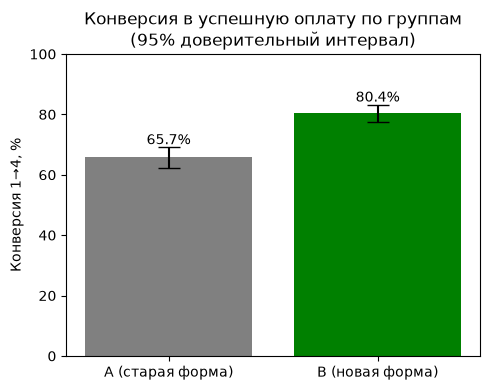

In [127]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['A (старая форма)', 'B (новая форма)'], conv, yerr=err, capsize=8,
       color=['gray', 'green'])
for i, v in enumerate(conv):
    ax.text(i, v + err[i] + 1, f'{v:.1f}%', ha='center')
ax.set_ylabel('Конверсия 1→4, %')
ax.set_title('Конверсия в успешную оплату по группам\n(95% доверительный интервал)')
ax.set_ylim(0, 100)
plt.tight_layout()
plt.savefig('../figures/conversion_by_group.png', dpi=150)
plt.show()

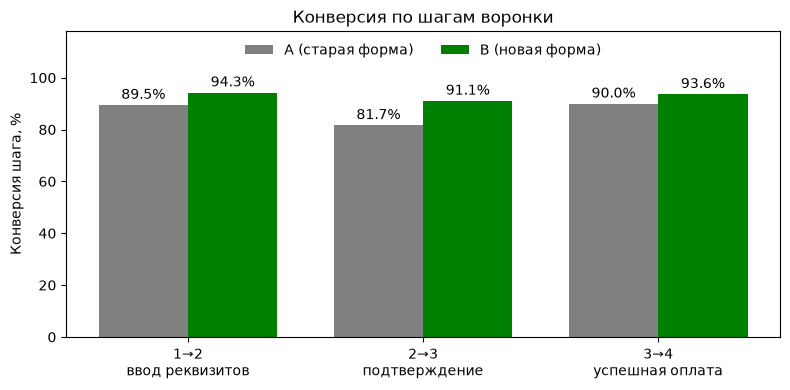

In [128]:
rate_a = [step_1_2_a * 100, step_2_3_a * 100, step_3_4_a * 100]
rate_b = [step_1_2_b * 100, step_2_3_b * 100, step_3_4_b * 100]


labels = ['1→2\nввод реквизитов', '2→3\nподтверждение', '3→4\nуспешная оплата']
x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
bars_a = ax.bar(x - w/2, rate_a, w, label='A (старая форма)', color='gray')
bars_b = ax.bar(x + w/2, rate_b, w, label='B (новая форма)', color='green')
ax.bar_label(bars_a, fmt='%.1f%%', padding=2)
ax.bar_label(bars_b, fmt='%.1f%%', padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Конверсия шага, %')
ax.set_ylim(0, 118)
ax.set_yticks(range(0, 101, 20))
ax.legend(loc='upper center', ncol=2, frameon=False)
ax.set_title('Конверсия по шагам воронки')
plt.tight_layout()
plt.savefig('../figures/funnel_by_step.png', dpi=150)
plt.show()

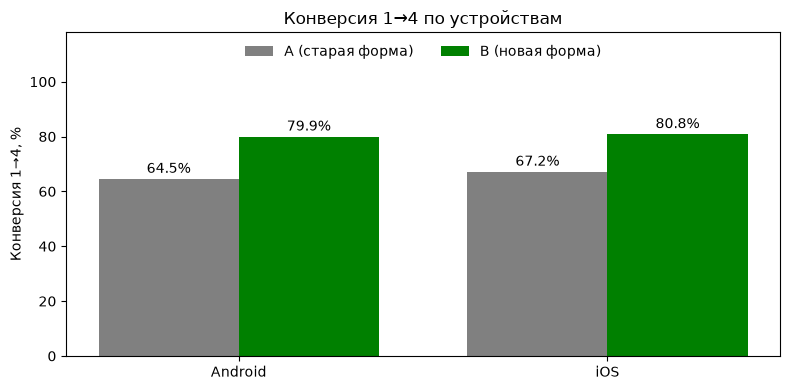

In [129]:
rate_a = (device_tests['conv_a'] * 100).tolist()
rate_b = (device_tests['conv_b'] * 100).tolist()

labels = ['Android', 'iOS']   
x = np.arange(len(labels))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
bars_a = ax.bar(x - w/2, rate_a, w, label='A (старая форма)', color='gray')
bars_b = ax.bar(x + w/2, rate_b, w, label='B (новая форма)', color='green')
ax.bar_label(bars_a, fmt='%.1f%%', padding=2)
ax.bar_label(bars_b, fmt='%.1f%%', padding=2)
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel('Конверсия 1→4, %')
ax.set_ylim(0, 118)
ax.set_yticks(range(0, 101, 20))
ax.legend(loc='upper center', ncol=2, frameon=False)
ax.set_title('Конверсия 1→4 по устройствам') 
plt.tight_layout()
plt.savefig('../figures/conversion_by_device.png', dpi=150)
plt.show()